## Non-Spatial Data Visualization

This notebook builds the non-spatial data visualizations that we will include in our dashboard. We will continue to build on exploration conducted by Lam Thieu in Week 3. We will aim to visualize some of the trends between acres burned, median income, and Fair Plan enrollment

### Import data and install packages

In [60]:
import pandas as pd
import seaborn as sns
from pathlib import Path
import matplotlib.ticker as ticker


# Set sns theme
sns.set_theme(
    style='white',
    font='sans-serif'
    )

In [2]:
root_fldr = Path.cwd().parent.parent
raw_fldr = root_fldr / 'data' / 'raw'
processed_fldr = root_fldr / 'data' / 'processed'

In [3]:
county_income = pd.read_csv(
    processed_fldr/'County_Income_CFP_2022_2024.csv',
    dtype={'GEOID': 'str'},
    )

county_fire = pd.read_csv(
    processed_fldr/'fire_by_county_2022_2024.csv',
    )
county_fire = county_fire.drop(columns=['Unnamed: 0', 'geometry'])

trends_data = pd.read_csv(
    processed_fldr/'County_Income_CFP_Fire_2022_2024.csv'
)

### Examine data and determine how to best visualize results

In [4]:
county_fire.head()

,fire_name,total_fire_acres,year,cause_description,fire_length_days,county_name,sqmi_burned,acres_burned,percent_fire_county
0,PARK,429603.0,2024,Arson,45,Butte County,82.650872,52896.557968,12.312893
1,PARK,429603.0,2024,Arson,45,Tehama County,588.606988,376708.472256,87.687580
2,YORK,93077.9,2023,Unknown/Unidentified,23,San Bernardino County,132.361888,84711.608635,91.011517
3,KELLY,89326.1,2023,Unknown/Unidentified,91,Del Norte County,120.007811,76804.999267,85.982707
4,MOSQUITO,76771.4,2022,Miscellaneous,46,El Dorado County,20.866813,13354.760600,17.395489


In [5]:
county_income.head()

,GEOID,county,year,Median_income,Income_MOE,policies,exposure
0,06001,Alameda,2022,122488,1231,2956,3047740652
1,06003,Alpine,2022,101125,17442,263,179049160
2,06005,Amador,2022,74853,6048,4041,2808434094
3,06007,Butte,2022,66085,2261,3722,2472656045
4,06009,Calaveras,2022,77526,3875,6983,4970383068


In [6]:
trends_data.head()

,county,policies_2022,policies_2023,policies_2024,policy_growth_pct,Median_income,acres_burned_total,income_group
0,Alameda,2956.0,3519.0,6774.0,129.161028,122488,2365.123992,Higher income
1,Alpine,263.0,297.0,346.0,31.558935,101125,32.593858,Higher income
2,Amador,4041.0,4742.0,5495.0,35.981193,74853,2828.727542,Middle income
3,Butte,3722.0,5878.0,8165.0,119.371306,66085,60036.571649,Lower income
4,Calaveras,6983.0,8520.0,9548.0,36.732064,77526,7390.358190,Middle income


### Start by comparing acres burned and Fair Plan enrollment

In [7]:
# Join Fair Plan and fire data
fire_totals = (
    county_fire
    .groupby(['county_name', 'year'], as_index=False)
    .agg(acres_burned_total=('acres_burned', 'sum'),
         total_fires = ('fire_name', 'count'))
)

fire_totals.head()

,county_name,year,acres_burned_total,total_fires
0,Alameda County,2022,1095.641596,9
1,Alameda County,2024,1269.482396,4
2,Alpine County,2023,32.593858,1
3,Amador County,2022,2587.972049,2
4,Amador County,2023,168.395056,4


In [8]:

# Remove ' County' so names match county_table ('Butte County' -> 'Butte')
fire_totals['county'] = fire_totals['county_name'].str.replace(' County', '')

fire_totals = fire_totals[['county', 'year', 'acres_burned_total', 'total_fires']]


all_data = pd.merge(
    left=county_income, 
    right=fire_totals,
    on=['county', 'year']
)

all_data['acres_burned_total'] = all_data['acres_burned_total'].fillna(0)


In [48]:
all_data.head()

,GEOID,county,year,Median_income,Income_MOE,policies,exposure,acres_burned_total,total_fires
0,06001,Alameda,2022,122488,1231,2956,3047740652,1095.641596,9
1,06005,Amador,2022,74853,6048,4041,2808434094,2587.972049,2
2,06007,Butte,2022,66085,2261,3722,2472656045,819.379408,18
3,06009,Calaveras,2022,77526,3875,6983,4970383068,1894.984653,1
4,06013,Contra Costa,2022,120020,1496,1264,1386513747,449.502656,8


##### Build wide dataframe

In [49]:
data_wide = (
    all_data.
    pivot_table(
        index = 'county',
        columns= 'year',
        values=['policies', 'acres_burned_total', 'total_fires', 'Median_income']
    )
)

data_wide.columns = [f"{year}_{val}" for val, year in data_wide.columns]

data_wide = data_wide.reset_index()

data_wide.head()

,county,2022_Median_income,2023_Median_income,2024_Median_income,2022_acres_burned_total,2023_acres_burned_total,2024_acres_burned_total,2022_policies,2023_policies,2024_policies,2022_total_fires,2023_total_fires,2024_total_fires
0,Alameda,122488.0,NaN,129367.0,1095.641596,NaN,1269.482396,2956.0,NaN,6774.0,9.0,NaN,4.0
1,Alpine,NaN,110781.0,NaN,NaN,32.593858,NaN,NaN,297.0,NaN,NaN,1.0,NaN
2,Amador,74853.0,81526.0,88044.0,2587.972049,168.395056,72.360437,4041.0,4742.0,5495.0,2.0,4.0,2.0
3,Butte,66085.0,68574.0,67928.0,819.379408,180.361682,59036.830558,3722.0,5878.0,8165.0,18.0,6.0,16.0
4,Calaveras,77526.0,79877.0,78647.0,1894.984653,139.482598,5355.890939,6983.0,8520.0,9548.0,1.0,2.0,2.0


We saw the largest increase in Fair Plan enrollment from 2023-2024. I'll start by comparing 2023 fires to 2024 enrollment

In [50]:
data_wide = data_wide.assign(
    policy_pct_change = lambda df: (df['2024_policies'] / df['2023_policies'] - 1) * 100
)

fp_fire_comp = data_wide[['county','policy_pct_change', '2023_acres_burned_total', '2023_total_fires']]

fp_fire_comp.info()

<class 'pandas.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   county                   53 non-null     str    
 1   policy_pct_change        36 non-null     float64
 2   2023_acres_burned_total  41 non-null     float64
 3   2023_total_fires         41 non-null     float64
dtypes: float64(3), str(1)
memory usage: 1.8 KB


In [18]:
fire_plot_data = (fp_fire_comp
                  .loc[(fp_fire_comp['2023_acres_burned_total'] > 0) & (fp_fire_comp['policy_pct_change'] > 0)]
                  )

In [24]:
data_wide_2223 = data_wide.assign(
    policy_pct_change = lambda df: (df['2023_policies'] / df['2022_policies'] - 1) * 100
)

fp_fire_comp_2223 = data_wide[['county','policy_pct_change', '2022_acres_burned_total', '2022_total_fires']]


fire_plot_data_22_23 = (fp_fire_comp_2223
                  .loc[(fp_fire_comp_2223['2022_acres_burned_total'] > 0) & (fp_fire_comp_2223['policy_pct_change'] > 0)]
                  )

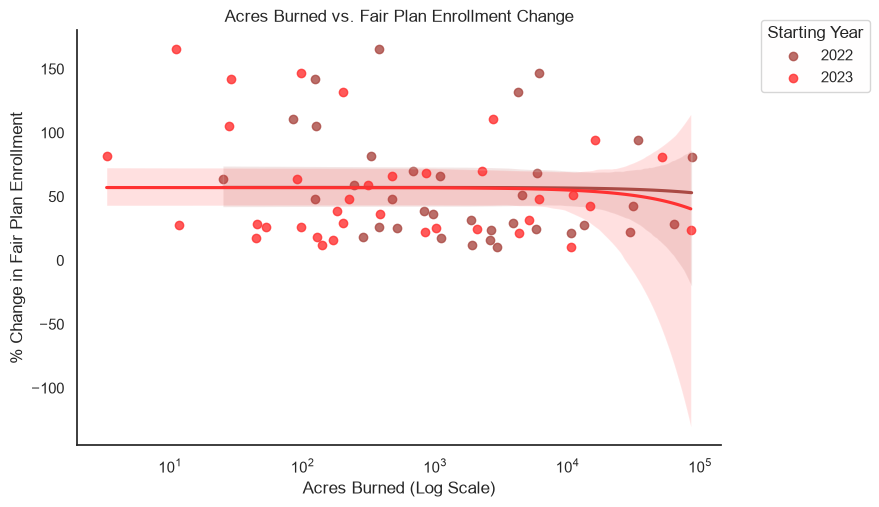

In [46]:
# plot all data on one chart
fire_plot_data_all = pd.concat(
    [(fire_plot_data_22_23.assign(starting_year = 2022).rename(
        columns={'2022_acres_burned_total':'acres_burned_total','2022_total_fires':'total_fires'}
        )), (fire_plot_data.assign(starting_year = 2023).rename(
        columns={'2023_acres_burned_total':'acres_burned_total','2023_total_fires':'total_fires'}
        ))], ignore_index=True
)

colors = {2022:'#AA4A44', 2023:'#FF3131'}

g = sns.lmplot(
    data=fire_plot_data_all,
    x='acres_burned_total',
    y='policy_pct_change',
    hue='starting_year',
    palette=colors,
    aspect=1.5,
   # ci=None
).set(
    title='Acres Burned vs. Fair Plan Enrollment Change',
    xlabel='Acres Burned (Log Scale)',
    ylabel='% Change in Fair Plan Enrollment',
    xscale='log'
)

sns.move_legend(
    g,
    title='Starting Year',
    loc = 'upper left',
    frameon=True,
    bbox_to_anchor = (0.9,1),
    facecolor="#FFFEFE"
)

The relationship between acres burned and % change in Fair Plan enrollment does not seem to be strong as shown in the above visualization.

In [99]:
# Split wildfire risk by percentiles, visualize Fair Plan enrollment
fire_fair_plan_data = all_data[['county', 'year', 'acres_burned_total', 'policies', 'exposure']].sort_values(['county', 'year']).reset_index(drop=True)

fire_fair_plan_data["policies_pct_change"] = (
    fire_fair_plan_data.groupby("county")["policies"].pct_change() * 100
)

fire_fair_plan_data = fire_fair_plan_data.assign(
    dollars_per_policy = lambda df: df['exposure']/df['policies']
)

fire_fair_plan_data.head()

fire_fair_plan_data['fire_risk'] = (
    fire_fair_plan_data.groupby('year')['acres_burned_total']
    .transform(
        lambda df: pd.qcut(
            df,
            q=4,
            labels=['1. Lowest Risk', '2. Low-Moderate Risk', '3. High-Moderate Risk', '4. High Risk'],
            duplicates='drop'
        )
    )
)

fire_fair_plan_data.head()

,county,year,acres_burned_total,policies,exposure,policies_pct_change,dollars_per_policy,fire_risk
0,Alameda,2022,1095.641596,2956,3047740652,NaN,1.031035e+06,3. High-Moderate Risk
1,Alameda,2024,1269.482396,6774,9822579031,129.161028,1.450041e+06,2. Low-Moderate Risk
2,Alpine,2023,32.593858,297,222282425,NaN,7.484257e+05,1. Lowest Risk
3,Amador,2022,2587.972049,4041,2808434094,NaN,6.949849e+05,3. High-Moderate Risk
4,Amador,2023,168.395056,4742,3526367836,17.347191,7.436457e+05,2. Low-Moderate Risk


In [101]:
group_policies = (
    fire_fair_plan_data
    .pivot_table(
        index='fire_risk',
        columns='year',
        values='policies',
        aggfunc='sum',
        observed=True
    ).reset_index()
)

group_index = group_policies.copy()
for year in [2022, 2023, 2024]:
    group_index[year] = group_policies[year] / group_policies[2022] * 100

group_index

year,fire_risk,2022,2023,2024
0,1. Lowest Risk,100.0,328.522536,300.542425
1,2. Low-Moderate Risk,100.0,194.452033,546.432520
2,3. High-Moderate Risk,100.0,154.317750,113.349638
3,4. High Risk,100.0,57.084001,147.391380


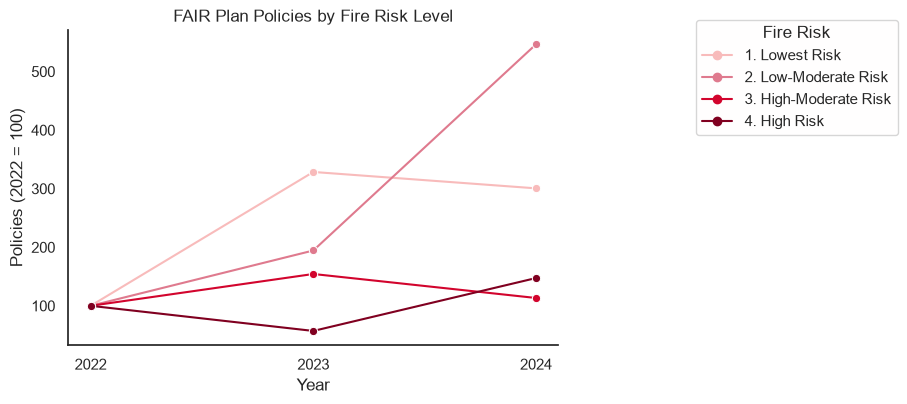

In [108]:
group_trend = group_index.melt(
    id_vars='fire_risk',
    var_name='year',
    value_name='policies_index'
)
group_trend['year'] = group_trend['year'].astype(int)

colors = {'1. Lowest Risk':"#F8BBBB", '2. Low-Moderate Risk':"#DF7A8E", '3. High-Moderate Risk':"#D2042D", '4. High Risk':'#800020'}

g = sns.relplot(
    data=group_trend,
    x='year',
    y='policies_index',
    hue='fire_risk',
    palette=colors,
    kind='line',
    marker='o',
    height=4,
    aspect=1.5,
).set(
    title  = 'FAIR Plan Policies by Fire Risk Level',
    xlabel = 'Year',
    ylabel = 'Policies (2022 = 100)',
    xticks = [2022, 2023, 2024],
 )

sns.move_legend(
    g,
    title='Fire Risk',
    loc = 'upper left',
    frameon=True,
    bbox_to_anchor = (0.9,1),
    facecolor="#FFFEFE"
)

### Comparing income and wildfire risk

Income and wildfire risk can be considered our indepedent variables in this analysis. To that end, this comparison will allow us to understand what relationship these variables have, allowing us to inform our regression analysis

In [63]:
income_fire_data = all_data[['county', 'year', 'Median_income', 'acres_burned_total']]

income_fire_data = income_fire_data.loc[income_fire_data['acres_burned_total'] > 0]

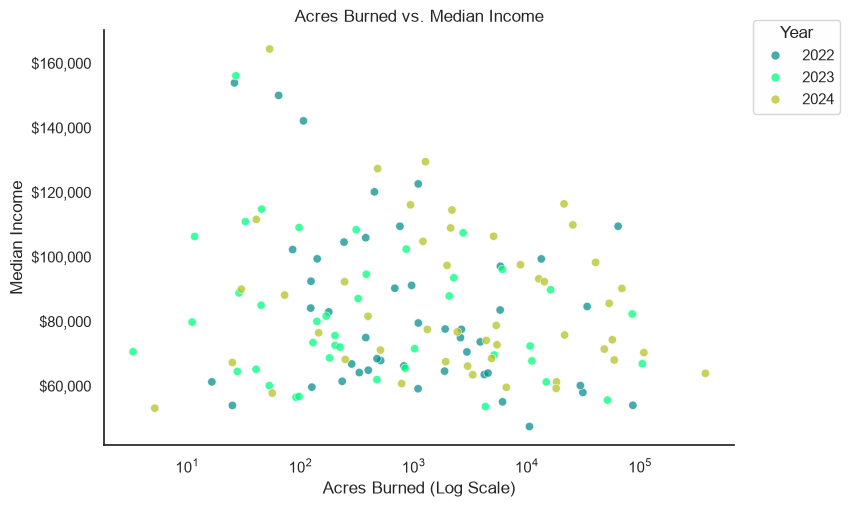

In [64]:
colors={2022:'#088F8F', 2023:'#00FF7F', 2024:'#B4C424'}

g = sns.relplot(
    data=income_fire_data,
    x='acres_burned_total',
    y='Median_income',
    hue='year',
    palette=colors,
    aspect=1.5,
    alpha=0.75
).set(
    title='Acres Burned vs. Median Income',
    xlabel='Acres Burned (Log Scale)',
    ylabel='Median Income',
    xscale='log'
)

g.ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))

sns.move_legend(
    g,
    title='Year',
    loc = 'upper left',
    frameon=True,
    bbox_to_anchor = (0.9,1),
    facecolor="#FFFEFE"
)



### Comparing income and Fair Plan enrollment

In [80]:
income_fair_plan_data = all_data[['county', 'year', 'Median_income', 'policies', 'exposure']].sort_values(['county', 'year']).reset_index(drop=True)

income_fair_plan_data["policies_pct_change"] = (
    income_fair_plan_data.groupby("county")["policies"].pct_change() * 100
)

income_fair_plan_data = income_fair_plan_data.assign(
    dollars_per_policy = lambda df: df['exposure']/df['policies']
)

income_fair_plan_data.head()


,county,year,Median_income,policies,exposure,policies_pct_change,dollars_per_policy
0,Alameda,2022,122488,2956,3047740652,NaN,1.031035e+06
1,Alameda,2024,129367,6774,9822579031,129.161028,1.450041e+06
2,Alpine,2023,110781,297,222282425,NaN,7.484257e+05
3,Amador,2022,74853,4041,2808434094,NaN,6.949849e+05
4,Amador,2023,81526,4742,3526367836,17.347191,7.436457e+05


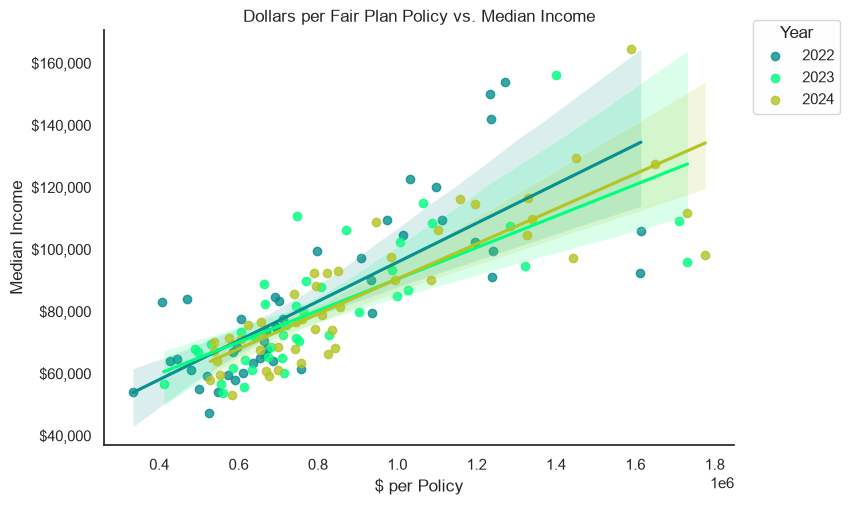

In [89]:
# visualize income vs. $ per policy

colors = {2022:'#088F8F', 2023:'#00FF7F', 2024:'#B4C424'}

g = sns.lmplot(
    data=income_fair_plan_data,
    x='dollars_per_policy',
    y='Median_income',
    hue='year',
    palette=colors,
    aspect=1.5,
   # ci=None
).set(
    title='Dollars per Fair Plan Policy vs. Median Income',
    xlabel='$ per Policy',
    ylabel='Median Income',
    #xscale='log'
)

g.ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))

sns.move_legend(
    g,
    title='Year',
    loc = 'upper left',
    frameon=True,
    bbox_to_anchor = (0.9,1),
    facecolor="#FFFEFE"
)

Unsurprisingly, wealthier counties have higher coverage per policy. We do not see major step changes year-over-year.

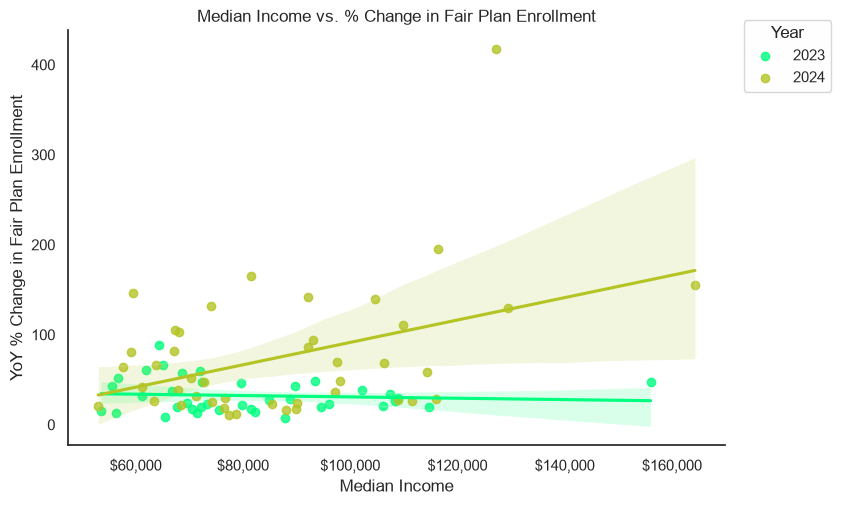

In [87]:
# comparing enrollment and median income
colors = {2023:'#00FF7F', 2024:'#B4C424'}

g = sns.lmplot(
    data=income_fair_plan_data.loc[income_fair_plan_data['year'] > 2022],
    x='Median_income',
    y='policies_pct_change',
    hue='year',
    palette=colors,
    aspect=1.5,
   # ci=None
).set(
    title='Median Income vs. % Change in Fair Plan Enrollment',
    xlabel='Median Income',
    ylabel='YoY % Change in Fair Plan Enrollment',
)

g.ax.xaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))

sns.move_legend(
    g,
    title='Year',
    loc = 'upper left',
    frameon=True,
    bbox_to_anchor = (0.9,1),
    facecolor="#FFFEFE"
)